# hsk: one sketch, multiple jobs

A single-pass low-rank sketch that you can **stream into, delete from, merge, persist and window**,
all without ever holding the matrix in memory.

The running example is a 5,000 x 5,000 sparse "who interacts with what" matrix with six planted communities
(a clearly separated spectrum plus a little sparse noise). We use it to show:

1. **Stream and factorize** in one pass, checked against SciPy's `svds`
2. **Shard and merge**: four workers, one answer
3. **Exact deletion** ("right to be forgotten") without recomputing anything
4. **Disk-backed state** that survives a restart
5. **Sliding-window anomaly detection** with `RollingFactorStream`
6. **Flat memory** while streaming

Everything printed is measured on the repo's creator's laptop. Nothing here is asserted in advance.

In [5]:
import os, time, tempfile
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import svds
import matplotlib.pyplot as plt
import hsk

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
RESULTS = {}   # filled in as we go, summarized at the end

print("hsk backend:", hsk.BACKEND)
if hsk.BACKEND != "native":
    print("WARNING: native backend not active. Blob (to_bytes/from_bytes) cells will be skipped.")


def subspace_sin(U_ref, U_est):
    """Largest sine of the principal angles between two equal-width orthonormal bases (0 = same subspace)."""
    c = np.linalg.svd(U_ref.T @ U_est, compute_uv=False)
    return float(np.sqrt(max(0.0, 1.0 - c.min() ** 2)))


def timed(fn, *a, **k):
    t0 = time.perf_counter()
    out = fn(*a, **k)
    return out, time.perf_counter() - t0

hsk backend: native


## 0. The data: six planted communities

Each community is a sparse rank-1 block (500 rows x 500 columns) with weight 100, 70, 50, 35, 25, 18,
plus 200k entries of small sparse noise. The matrix has about 1.7M entries, shuffled into arbitrary order,
which is how a real event log looks.

In [6]:
rng = np.random.default_rng(7)
m = n = 5000
K = 6                                            # planted rank
weights = np.array([100, 70, 50, 35, 25, 18.0])
support = 500

R, C, V = [], [], []
for w in weights:
    ri = rng.choice(m, support, replace=False)
    ci = rng.choice(n, support, replace=False)
    u = rng.standard_normal(support); u /= np.linalg.norm(u)
    v = rng.standard_normal(support); v /= np.linalg.norm(v)
    R.append(np.repeat(ri, support))
    C.append(np.tile(ci, support))
    V.append(w * np.outer(u, v).ravel())
nn = 200_000                                      # sparse background noise
R.append(rng.integers(0, m, nn)); C.append(rng.integers(0, n, nn)); V.append(0.01 * rng.standard_normal(nn))

rows = np.concatenate(R).astype(np.int64)
cols = np.concatenate(C).astype(np.int64)
vals = np.concatenate(V).astype(np.float64)
perm = rng.permutation(len(vals))                 # arrive in arbitrary order
rows, cols, vals = rows[perm], cols[perm], vals[perm]
nnz = len(vals)

# Reference answer (this is the thing hsk does NOT need: the whole matrix in memory)
A = sp.coo_matrix((vals, (rows, cols)), shape=(m, n)).tocsr()
(U_ref, S_ref, Vt_ref), t_svds = timed(svds, A, k=K)
order = np.argsort(-S_ref); U_ref, S_ref, Vt_ref = U_ref[:, order], S_ref[order], Vt_ref[order]
Ac = A.tocoo()                                    # duplicates summed: the distinct entries of the matrix
csr_bytes = A.data.nbytes + A.indices.nbytes + A.indptr.nbytes

print(f"{m}x{n}, {nnz:,} entries streamed in arbitrary order")
print("true top-6 singular values (svds):", np.round(S_ref, 3), f"  [{t_svds:.2f} s]")

5000x5000, 1,700,000 entries streamed in arbitrary order
true top-6 singular values (svds): [100.093  69.934  50.011  34.992  24.963  17.973]   [0.11 s]


## 1. Stream, then factorize

Ten batches go in; each batch is thrown away after `update_coo`. Then one `finalize`.

stream: 0.182 s (9.34 M entries/s)   finalize: 0.033 s
sketch state: 6.4 MB   (CSR copy of the same data: 19.8 MB)

 i |   true      hsk     rel.err
 0 |  100.093  100.152   5.95e-04
 1 |   69.934   69.863   1.01e-03
 2 |   50.011   49.963   9.75e-04
 3 |   34.992   35.115   3.52e-03
 4 |   24.963   25.059   3.85e-03
 5 |   17.973   18.042   3.81e-03

left-subspace sin(theta_max) = 5.87e-02   (0 = identical)
rank-6 reconstruction error over the matrix's entries: hsk 3.279e-02   exact svds 3.180e-02
extra components (should be small, they are sketch padding): [0.715 0.689]


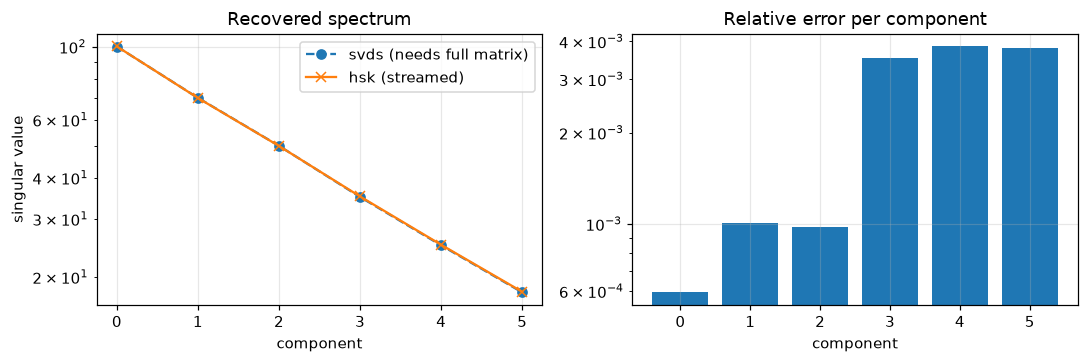

In [7]:
RANK, OV, SEED = 8, 24, 42      # rank 8 + oversample 24 = sketch width 32
batches = np.array_split(np.arange(nnz), 10)

sk = hsk.StreamingSketch(m, n, rank=RANK, oversample=OV, seed=SEED)
t0 = time.perf_counter()
for idx in batches:
    sk.update_coo(rows[idx], cols[idx], vals[idx])
t_stream = time.perf_counter() - t0
(U, S, V), t_fin = timed(sk.finalize, RANK)       # note: V is n x k (not V transpose)

rel = np.abs(S[:K] - S_ref) / S_ref
sin = subspace_sin(U_ref, U[:, :K])

def fit_residual(Uk, Sk, Vk):                     # rank-6 reconstruction error over the matrix's distinct entries
    pred = np.einsum("ij,j,ij->i", Uk[Ac.row], Sk, Vk[Ac.col])
    return np.linalg.norm(Ac.data - pred) / np.linalg.norm(Ac.data)

fit_hsk = fit_residual(U[:, :K], S[:K], V[:, :K])
fit_exact = fit_residual(U_ref, S_ref, Vt_ref.T)

print(f"stream: {t_stream:.3f} s ({nnz / t_stream / 1e6:.2f} M entries/s)   finalize: {t_fin:.3f} s")
print(f"sketch state: {sk.memory_bytes() / 1e6:.1f} MB   (CSR copy of the same data: {csr_bytes / 1e6:.1f} MB)")
print()
print(" i |   true      hsk     rel.err")
for i in range(K):
    print(f"{i:2d} | {S_ref[i]:8.3f} {S[i]:8.3f}   {rel[i]:.2e}")
print(f"\nleft-subspace sin(theta_max) = {sin:.2e}   (0 = identical)")
print(f"rank-6 reconstruction error over the matrix's entries: hsk {fit_hsk:.3e}   exact svds {fit_exact:.3e}")
print("extra components (should be small, they are sketch padding):", np.round(S[K:], 3))

RESULTS["stream_M_per_s"] = nnz / t_stream / 1e6
RESULTS["top_sv_rel_err"] = float(rel[0]); RESULTS["worst_sv_rel_err"] = float(rel.max())
RESULTS["subspace_sin"] = sin; RESULTS["fit_hsk"] = fit_hsk; RESULTS["fit_exact"] = fit_exact

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].semilogy(range(K), S_ref, "o--", label="svds (needs full matrix)")
ax[0].semilogy(range(K), S[:K], "x-", label="hsk (streamed)")
ax[0].set(title="Recovered spectrum", xlabel="component", ylabel="singular value"); ax[0].legend()
ax[1].bar(range(K), rel); ax[1].set_yscale("log")
ax[1].set(title="Relative error per component", xlabel="component")
plt.tight_layout(); plt.show()

## 2. Shard and merge

Four workers each see a quarter of the stream and build their own sketch (same seed). Merging is just addition,
so the merged sketch equals the one built from the whole stream, up to floating-point rounding.

In [8]:
shard_ids = np.array_split(rng.permutation(nnz), 4)
parts = []
for ids in shard_ids:
    s = hsk.StreamingSketch(m, n, rank=RANK, oversample=OV, seed=SEED)
    s.update_coo(rows[ids], cols[ids], vals[ids])
    parts.append(s)

blobs = [p.to_bytes() for p in parts] if hsk.BACKEND == "native" else None   # taken before merging

merged = parts[0]
for p in parts[1:]:
    merged.merge(p)

d_yt = np.abs(merged.yt - sk.yt).max() / np.abs(sk.yt).max()
d_w = np.abs(merged.w - sk.w).max() / np.abs(sk.w).max()
S_m = merged.finalize(RANK)[1]
print(f"merged vs single-pass sketch: max relative diff  Yt {d_yt:.1e}   W {d_w:.1e}")
print(f"top singular value: merged {S_m[0]:.6f}   single {S[0]:.6f}")
RESULTS["merge_rel_diff"] = float(max(d_yt, d_w))

merged vs single-pass sketch: max relative diff  Yt 2.3e-15   W 2.1e-15
top singular value: merged 100.152074   single 100.152074


In [9]:
if blobs is None:
    print("skipped: blobs need the native backend")
else:
    print(f"each worker ships {len(blobs[0]) / 1e6:.2f} MB (this is also what a DuckDB BLOB column holds)")
    agg = hsk.StreamingSketch.from_bytes(blobs[0])
    for b in blobs[1:]:
        agg.merge_bytes(b)                       # adds straight from bytes, no object built
    d = np.abs(agg.yt - sk.yt).max() / np.abs(sk.yt).max()
    print(f"merged from raw blobs: max relative diff vs single-pass  Yt {d:.1e}")
    RESULTS["blob_merge_rel_diff"] = float(d)

each worker ships 6.40 MB (this is also what a DuckDB BLOB column holds)
merged from raw blobs: max relative diff vs single-pass  Yt 2.3e-15


## 3. Exact deletion

A user asks to be forgotten: 500 rows (people), every entry they ever contributed. We *subtract* those entries
from the live sketch and compare with a sketch rebuilt from scratch on the remaining data.
There is no retraining step and no second pass over the surviving data.

In [10]:
forget_rows = rng.choice(m, 500, replace=False)
mask = np.isin(rows, forget_rows)
print(f"forgetting {len(forget_rows)} rows = {mask.sum():,} of {nnz:,} entries")

live = hsk.StreamingSketch(m, n, rank=RANK, oversample=OV, seed=SEED)          # the "production" sketch
live.update_coo(rows, cols, vals)
live.update_coo(rows[mask], cols[mask], -vals[mask])              # the deletion: just negative values

fresh = hsk.StreamingSketch(m, n, rank=RANK, oversample=OV, seed=SEED)         # ground truth: rebuilt without those rows
fresh.update_coo(rows[~mask], cols[~mask], vals[~mask])

d_yt = np.abs(live.yt - fresh.yt).max() / np.abs(fresh.yt).max()
d_w = np.abs(live.w - fresh.w).max() / np.abs(fresh.w).max()
S_live, S_fresh = live.finalize(RANK)[1], fresh.finalize(RANK)[1]

A_keep = sp.coo_matrix((vals[~mask], (rows[~mask], cols[~mask])), shape=(m, n)).tocsr()
S_true_keep = np.sort(svds(A_keep, k=K, return_singular_vectors=False))[::-1]

print(f"after delete vs rebuilt-from-scratch: max relative diff  Yt {d_yt:.1e}   W {d_w:.1e}")
print("top-6 after deletion  (live sketch):", np.round(S_live[:K], 3))
print("top-6 after deletion  (svds on kept):", np.round(S_true_keep, 3))
RESULTS["delete_rel_diff"] = float(max(d_yt, d_w))

forgetting 500 rows = 166,241 of 1,700,000 entries
after delete vs rebuilt-from-scratch: max relative diff  Yt 1.6e-15   W 1.8e-15
top-6 after deletion  (live sketch): [93.799 65.944 47.632 32.819 24.098 17.414]
top-6 after deletion  (svds on kept): [93.703 65.943 47.687 32.812 24.034 17.355]


## 4. Disk-backed state

`create_memmap` puts the sketch state into files and the native code updates it in place.
Close, reopen later, and carry on. No save step and no serialization.

In [11]:
tmp = tempfile.mkdtemp(prefix="hsk_demo_")
path = os.path.join(tmp, "state")

with hsk.StreamingSketch.create_memmap(path, m, n, RANK, oversample=OV, seed=SEED) as mm:
    for idx in batches[:5]:
        mm.update_coo(rows[idx], cols[idx], vals[idx])           # first half of the stream

print("files on disk:", {f: f"{os.path.getsize(os.path.join(tmp, f)) / 1e6:.2f} MB" for f in sorted(os.listdir(tmp))})

# ... process restarts ...
mm2 = hsk.StreamingSketch.open_memmap(path)
for idx in batches[5:]:
    mm2.update_coo(rows[idx], cols[idx], vals[idx])              # second half
S_mm = mm2.finalize(RANK)[1]
mm2.close()

print(f"max |S_memmap - S_single| over all {RANK} values: {np.abs(S_mm - S).max():.2e}")
RESULTS["memmap_sv_diff"] = float(np.abs(S_mm - S).max())

files on disk: {'state.hsk.json': '0.00 MB', 'state.w.f64': '5.12 MB', 'state.yt.f64': '1.28 MB'}
max |S_memmap - S_single| over all 8 values: 0.00e+00


## 5. Streaming anomaly detection with `RollingFactorStream`

A 400-sensor system is observed through a stream of readings: each tick delivers 150 column vectors.
In normal operation every column is a mixture of four hidden factors plus a little noise.
Between ticks 120 and 123 the system misbehaves and columns point in unrelated directions.

`RollingFactorStream` keeps a 40-tick window by streaming new ticks in and **subtracting expired ones**.
`push` returns an anomaly score: the fraction of the new batch's energy outside the window's top-4 subspace.

200 ticks in 1.34 s (6.7 ms per tick incl. a factorization each tick)
baseline score: mean 0.153, std 0.047   threshold (mean + 6 std): 0.433
anomalous ticks injected: [120, 121, 122, 123]
ticks flagged           : [120, 121, 122, 123]
top-4 singular values of the current window: [317.2  233.66 157.97 115.68]


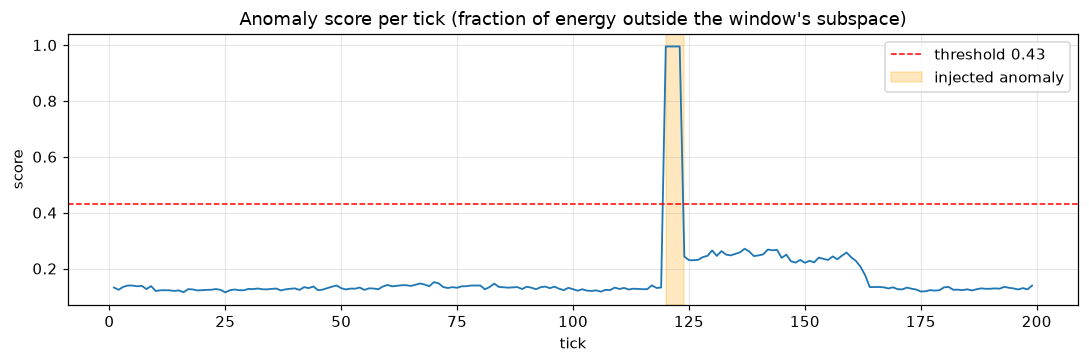

In [12]:
rng2 = np.random.default_rng(11)
ms, ns, r0 = 400, 1500, 4
Bf = np.linalg.qr(rng2.standard_normal((ms, r0)))[0]               # the four hidden factors
amp = np.array([4.0, 3.0, 2.0, 1.5])
T, ANOM = 200, range(120, 124)
COLS_PER_TICK = 150

def make_tick(t):
    cj = rng2.choice(ns, COLS_PER_TICK, replace=False)
    if t in ANOM:
        X = rng2.standard_normal((ms, COLS_PER_TICK)) * (np.linalg.norm(amp) / np.sqrt(ms))   # off-subspace, same energy
    else:
        X = Bf @ (amp[:, None] * rng2.standard_normal((r0, COLS_PER_TICK))) + 0.03 * rng2.standard_normal((ms, COLS_PER_TICK))
    return np.tile(np.arange(ms), COLS_PER_TICK), np.repeat(cj, ms), X.ravel(order="F")

rs = hsk.RollingFactorStream(ms, ns, rank=r0, window=40, refresh_every=1, rebuild_every=100, seed=5)
scores = np.full(T, np.nan)
t0 = time.perf_counter()
for t in range(T):
    r, c, v = make_tick(t)
    scores[t] = rs.push(r, c, v)
t_roll = time.perf_counter() - t0

base = scores[[t for t in range(5, T) if t not in ANOM]]
thr = np.nanmean(base) + 6 * np.nanstd(base)
flagged = [t for t in range(T) if scores[t] > thr]
print(f"{T} ticks in {t_roll:.2f} s ({t_roll / T * 1e3:.1f} ms per tick incl. a factorization each tick)")
print(f"baseline score: mean {np.nanmean(base):.3f}, std {np.nanstd(base):.3f}   threshold (mean + 6 std): {thr:.3f}")
print("anomalous ticks injected:", list(ANOM))
print("ticks flagged           :", flagged)
print("top-4 singular values of the current window:", np.round(rs.singular_values(r0), 2))
RESULTS["anomaly_flagged"] = flagged

plt.figure(figsize=(10, 3.4))
plt.plot(scores, lw=1.2)
plt.axhline(thr, color="red", ls="--", lw=1, label=f"threshold {thr:.2f}")
plt.axvspan(min(ANOM), max(ANOM) + 1, color="orange", alpha=0.25, label="injected anomaly")
plt.setp(plt.gca(), title="Anomaly score per tick (fraction of energy outside the window's subspace)", xlabel="tick", ylabel="score")
plt.legend(); plt.tight_layout(); plt.show()

## 6. Memory while streaming

We stream 20 batches of 1,000,000 fresh random entries (20M in total) into a 10,000 x 10,000 sketch, and watch the
process's resident memory. Each batch is generated, consumed and dropped. The "CSR" figure is the estimated size of
holding the same 20M entries as a SciPy matrix (8 B value + 4 B index each), not something we build.

In [13]:
try:
    import psutil
except ImportError:
    psutil = None
    print("pip install psutil to run this cell")

if psutil is not None:
    N_BATCHES, BATCH = 20, 1_000_000
    mm_, nn_ = 10_000, 10_000
    proc = psutil.Process()
    rng3 = np.random.default_rng(3)
    skm = hsk.StreamingSketch(mm_, nn_, rank=16, seed=1)
    rss0 = proc.memory_info().rss
    peak = rss0
    t0 = time.perf_counter()
    for b in range(N_BATCHES):
        r = rng3.integers(0, mm_, BATCH, dtype=np.int64)
        c = rng3.integers(0, nn_, BATCH, dtype=np.int64)
        v = rng3.standard_normal(BATCH)
        skm.update_coo(r, c, v)
        peak = max(peak, proc.memory_info().rss)
    dt = time.perf_counter() - t0
    total = N_BATCHES * BATCH
    csr_est = total * 12 + (mm_ + 1) * 4
    print(f"streamed {total / 1e6:.0f}M entries in {dt:.2f} s ({total / dt / 1e6:.2f} M entries/s)")
    print(f"sketch state: {skm.memory_bytes() / 1e6:.1f} MB")
    print(f"process RSS growth over the run (peak - start): {(peak - rss0) / 1e6:.1f} MB   (includes one 1M-entry batch, ~24 MB)")
    print(f"estimated CSR for the same entries: {csr_est / 1e6:.0f} MB")
    RESULTS["mem_growth_MB"] = (peak - rss0) / 1e6
    RESULTS["csr_estimate_MB"] = csr_est / 1e6

streamed 20M entries in 3.23 s (6.19 M entries/s)
sketch state: 10.4 MB
process RSS growth over the run (peak - start): 24.0 MB   (includes one 1M-entry batch, ~24 MB)
estimated CSR for the same entries: 240 MB


## 7. How fast is ingestion?

**Idea:** every update touches only a small fixed-size slice of the sketch, so the cost per entry does not depend on how many entries came before.

- 1,000,000 random entries into a 10,000 × 10,000 sketch (rank 16): about **0.1–0.14 s, roughly 7–10 million entries per second** (it varies from run to run).
- The sketch state is a fixed **10.4 MB**, however many entries you stream.

*Single run on a laptop with uniformly random indices. Timing only; no factors are computed here.*

In [15]:
# Ingestion throughput: single run, machine-dependent. Timing only; no factors are computed.
import time
import numpy as np
import hsk

m = n = 10_000
nnz = 1_000_000
g = np.random.default_rng(0)
r = g.integers(0, m, nnz, dtype=np.int64)
c = g.integers(0, n, nnz, dtype=np.int64)
v = g.standard_normal(nnz)

sk_t = hsk.StreamingSketch(m, n, rank=16, seed=42)
t0 = time.perf_counter()
sk_t.update_coo(r, c, v)
dt = time.perf_counter() - t0
print(f"{nnz:,} entries into a {m:,} x {n:,} sketch (rank 16): {dt:.3f} s  ({nnz / dt / 1e6:.1f} M entries/s)")
print(f"sketch state: {sk_t.memory_bytes() / 1e6:.1f} MB")

1,000,000 entries into a 10,000 x 10,000 sketch (rank 16): 0.139 s  (7.2 M entries/s)
sketch state: 10.4 MB


## 8. Does memory stay flat at scale?

**Idea:** the sketch is a fixed-size summary. The matrix itself is never stored, so memory should not grow as entries arrive.

- A **100,000 × 100,000** matrix, **350 million** entries streamed in 5M-entry batches.
- Sketch state: **99.2 MiB**, fixed by the formula 8·(l·m + s·n) bytes.
- Process memory growth stayed **constant (about 215 MiB in the last run) from 50M to 350M entries**. It includes the 5M-entry input batch generated in the loop, which is why it's above 99 MiB. Across runs it ranged from about 150 to 215 MiB.
- Speed at this size: about **2.5–4.5 million entries per second**, or **1.5–2.5 minutes** for the full run, varying by run. That is slower per entry than the small case, probably because a larger state is accessed more randomly.

*What this shows: bounded memory and steady streaming. It says nothing about accuracy, and no factors are computed here.* Accuracy is covered in the planted-community sections above.

In [17]:
# Scale demo: stream a 100,000 x 100,000 matrix in chunks. Reports time and memory only.
import os, time
import numpy as np
import hsk

try:
    import psutil
    proc = psutil.Process(os.getpid())
    rss = lambda: proc.memory_info().rss / 2**20
except ImportError:
    rss = None

M = N = 100_000
RANK = 16
TOTAL = 350_000_000      # we can lower this (e.g. 50_000_000) for a quick run
CHUNK = 5_000_000

g = np.random.default_rng(42)
base = rss() if rss else None
sk_big = hsk.StreamingSketch(M, N, rank=RANK, seed=42)
print(f"sketch state (formula): {sk_big.memory_bytes() / 2**20:.1f} MiB, fixed regardless of entries streamed")

done, t0 = 0, time.perf_counter()
while done < TOTAL:
    r = g.integers(0, M, CHUNK, dtype=np.int64)
    c = g.integers(0, N, CHUNK, dtype=np.int64)
    v = g.standard_normal(CHUNK)
    sk_big.update_coo(r, c, v)
    done += CHUNK
    if rss and (done // CHUNK) % 10 == 0:
        print(f"{done:>12,} entries | process RSS growth: {rss() - base:6.1f} MiB")
dt = time.perf_counter() - t0
print(f"\n{done:,} entries in {dt:.1f} s ({done / dt / 1e6:.1f} M entries/s)")
print("RSS growth includes the 5M-entry input batch generated in this loop, not only the sketch.")

sketch state (formula): 99.2 MiB, fixed regardless of entries streamed
  50,000,000 entries | process RSS growth:  215.3 MiB
 100,000,000 entries | process RSS growth:  215.4 MiB
 150,000,000 entries | process RSS growth:  215.4 MiB
 200,000,000 entries | process RSS growth:  215.4 MiB
 250,000,000 entries | process RSS growth:  215.4 MiB
 300,000,000 entries | process RSS growth:  215.4 MiB
 350,000,000 entries | process RSS growth:  215.4 MiB

350,000,000 entries in 77.4 s (4.5 M entries/s)
RSS growth includes the 5M-entry input batch generated in this loop, not only the sketch.


## Scorecard

In [ ]:
print(f"{'check':45s} value")
print("-" * 62)
rows_out = [
    ("stream throughput (M entries/s)", RESULTS.get("stream_M_per_s"), "{:.2f}"),
    ("top singular value, relative error", RESULTS.get("top_sv_rel_err"), "{:.2e}"),
    ("worst of top-6 singular values, rel. error", RESULTS.get("worst_sv_rel_err"), "{:.2e}"),
    ("subspace sin(theta_max), 0 = identical", RESULTS.get("subspace_sin"), "{:.2e}"),
    ("rank-6 reconstruction error: hsk", RESULTS.get("fit_hsk"), "{:.3e}"),
    ("rank-6 reconstruction error: exact svds", RESULTS.get("fit_exact"), "{:.3e}"),
    ("4-shard merge vs single pass (rel. diff)", RESULTS.get("merge_rel_diff"), "{:.1e}"),
    ("blob merge vs single pass (rel. diff)", RESULTS.get("blob_merge_rel_diff"), "{:.1e}"),
    ("delete vs rebuild (rel. diff)", RESULTS.get("delete_rel_diff"), "{:.1e}"),
    ("memmap restart vs single pass (max abs sv diff)", RESULTS.get("memmap_sv_diff"), "{:.1e}"),
    ("RSS growth while streaming 20M entries (MB)", RESULTS.get("mem_growth_MB"), "{:.1f}"),
]
for name, val, fmt in rows_out:
    print(f"{name:45s} {fmt.format(val) if val is not None else 'n/a'}")
print("anomaly ticks flagged:", RESULTS.get("anomaly_flagged"), " (injected: 120-123)")

check                                         value
--------------------------------------------------------------
stream throughput (M entries/s)               9.34
top singular value, relative error            5.95e-04
worst of top-6 singular values, rel. error    3.85e-03
subspace sin(theta_max), 0 = identical        5.87e-02
rank-6 reconstruction error: hsk              3.279e-02
rank-6 reconstruction error: exact svds       3.180e-02
4-shard merge vs single pass (rel. diff)      2.3e-15
blob merge vs single pass (rel. diff)         2.3e-15
delete vs rebuild (rel. diff)                 1.8e-15
memmap restart vs single pass (max abs sv diff) 0.0e+00
RSS growth while streaming 20M entries (MB)   24.0
anomaly ticks flagged: [120, 121, 122, 123]  (injected: 120-123)


### Reading the results honestly

* Section 1 works because the spectrum has a clear gap (smallest planted value 18 vs noise tail well below 1).
  A single-pass sketch will **not** recover the top values of a flat or noise-dominated matrix; use
  `hsk.rsvd_certified` when you can afford a second pass.
* Exactness in sections 2 and 3 is up to floating-point rounding, not bit-for-bit.